Execution Time: 7.216589749998093               checksum:  78513425


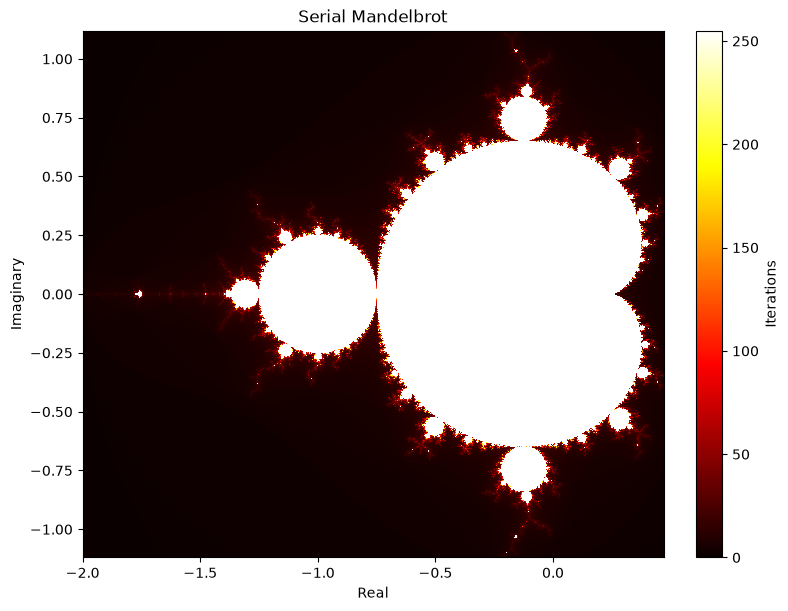

In [23]:
import os
import time
from math import sqrt

import matplotlib.pyplot as plt

height = 1024
width = 1024
min_x = -2.0
max_x = 0.47
min_y = -1.12
max_y = 1.12
scalex = (max_x - min_x) / width
scaley = (max_y - min_y) / height
MAX_ITERS = 256


def plot_mandelbrot(values, title):
    atlas = [values[row * width:(row + 1) * width] for row in range(height)]
    fig, axis = plt.subplots(figsize=(8, 6), constrained_layout=True)
    image = axis.imshow(
        atlas,
        extent=(min_x, max_x, min_y, max_y),
        origin="lower",
        interpolation="nearest",
        cmap="hot",
        aspect="equal",
    )
    axis.set_title(title)
    axis.set_xlabel("Real")
    axis.set_ylabel("Imaginary")
    fig.colorbar(image, ax=axis, label="Iterations")
    plt.show()


def run_benchmark(compute, title):
    start_time = time.perf_counter()
    values = compute()
    execution_time = time.perf_counter() - start_time
    checksum = sum(values)
    print("Execution Time:", execution_time, end=" ")
    print("              checksum: ", checksum)
    plot_mandelbrot(values, title)
    return values, execution_time


def mandelbrot_0(cx, cy):
    z_real = 0.0
    z_imag = 0.0
    iterations = 0

    for _ in range(1, MAX_ITERS):
        new_real = z_real * z_real - z_imag * z_imag + cx
        new_imag = z_imag * z_real + z_real * z_imag + cy
        if sqrt(new_real ** 2 + new_imag ** 2) > 2.0:
            break
        z_real = new_real
        z_imag = new_imag
        iterations += 1

    return iterations


def _mandelbrot_row_chunk(row_range):
    row_start, row_stop = row_range
    output = []

    for h in range(row_start, row_stop):
        cy = min_y + h * scaley
        for w in range(width):
            cx = min_x + w * scalex
            output.append(mandelbrot_0(cx, cy))

    return row_start * width, output


def assemble_mandelbrot(row_results):
    output = [0] * (height * width)
    for output_start, values in row_results:
        output[output_start:output_start + len(values)] = values
    return output


def mandelbrot_row_ranges():
    workers = min(os.cpu_count() or 1, height)
    chunk_size = max(1, (height + workers * 4 - 1) // (workers * 4))
    return [
        (start, min(start + chunk_size, height))
        for start in range(0, height, chunk_size)
    ]


def mandelbrot():
    row_results = map(_mandelbrot_row_chunk, mandelbrot_row_ranges())
    return assemble_mandelbrot(row_results)


result, serial_time = run_benchmark(mandelbrot, "Serial Mandelbrot")

In [ ]:
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import get_all_start_methods, get_context


def mandelbrot_process_pool():
    # Fork keeps notebook-defined worker functions available on macOS/Linux.
    context = get_context("fork") if "fork" in get_all_start_methods() else get_context()
    max_workers = os.cpu_count() or 1
    print(f"Using max_workers: {max_workers}")
    
    with ProcessPoolExecutor(max_workers=max_workers, mp_context=context) as executor:
        row_results = executor.map(
            _mandelbrot_row_chunk,
            mandelbrot_row_ranges(),
        )
        return assemble_mandelbrot(row_results)


parallel_result, parallel_time = run_benchmark(
    mandelbrot_process_pool,
    "ProcessPoolExecutor Mandelbrot",
)
print(f"Parallelism factor (serial / parallel): {serial_time / parallel_time:.2f}x")

Using max_workers: 18


Process SpawnProcess-218:
Process SpawnProcess-219:
Process SpawnProcess-217:
Process SpawnProcess-220:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/Users/janusz/.local/share/uv/python/cpython-3.13.13-macos-aarch64-none/lib/python3.13/multiprocessing/process.py", line 313, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/Users/janusz/.local/share/uv/python/cpython-3.13.13-macos-aarch64-none/lib/python3.13/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/janusz/.local/share/uv/python/cpython-3.13.13-macos-aarch64-none/lib/python3.13/concurrent/futures/process.py", line 242, in _process_worker
    call_item = call_queue.get(block=True)
  File "/Users/janusz/.local/share/uv/python/cpython-3.13.13-macos-aarch64-none/lib/python3.13/multiprocessing/queues.py", line 120, in get
    re

BrokenProcessPool: A process in the process pool was terminated abruptly while the future was running or pending.